# Assignment 1: Uber Fare Prediction
Dataset: [Uber Fares Dataset (Kaggle)](https://www.kaggle.com/datasets/yasserh/uber-fares-dataset)

Steps: pre-process -> identify outliers -> check correlation -> linear regression & random forest regression -> compare R2 / RMSE.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

pd.set_option("display.max_columns", None)

## Load the dataset

In [2]:
df = pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


## 1. Pre-process the dataset

In [4]:
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")], errors="ignore")
df = df.dropna().copy()

# Keep valid geographic coordinates only.
for col in ["pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude"]:
    df = df[df[col].between(-180, 180)]


def haversine(lat1, lon1, lat2, lon2):
    r = 6371  # Earth radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


df["distance_km"] = haversine(df.pickup_latitude, df.pickup_longitude, df.dropoff_latitude, df.dropoff_longitude)
df = df[(df.fare_amount > 0) & (df.distance_km > 0)]
print(f"Shape after cleaning: {df.shape}")

Shape after cleaning: (194335, 9)


## 2. Identify outliers

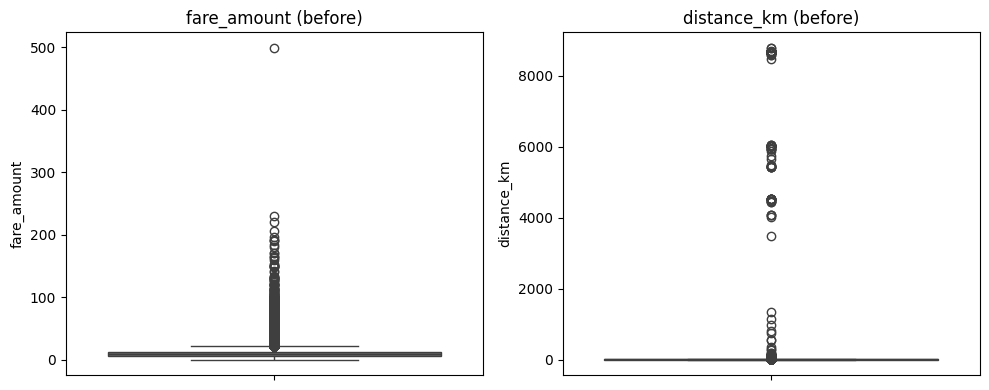

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df["fare_amount"], ax=axes[0]).set_title("fare_amount (before)")
sns.boxplot(y=df["distance_km"], ax=axes[1]).set_title("distance_km (before)")
plt.tight_layout()
plt.show()

In [6]:
def remove_outliers_iqr(data, column):
    q1, q3 = data[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = data[column].between(lower, upper)
    print(f"Outliers removed on '{column}': {(~mask).sum()} rows (bounds: [{lower:.2f}, {upper:.2f}])")
    return data[mask]


df = remove_outliers_iqr(df, "fare_amount")
df = remove_outliers_iqr(df, "distance_km")
print(f"Shape after outlier removal: {df.shape}")

Outliers removed on 'fare_amount': 16651 rows (bounds: [-3.75, 22.25])
Outliers removed on 'distance_km': 8045 rows (bounds: [-1.95, 6.51])
Shape after outlier removal: (169639, 9)


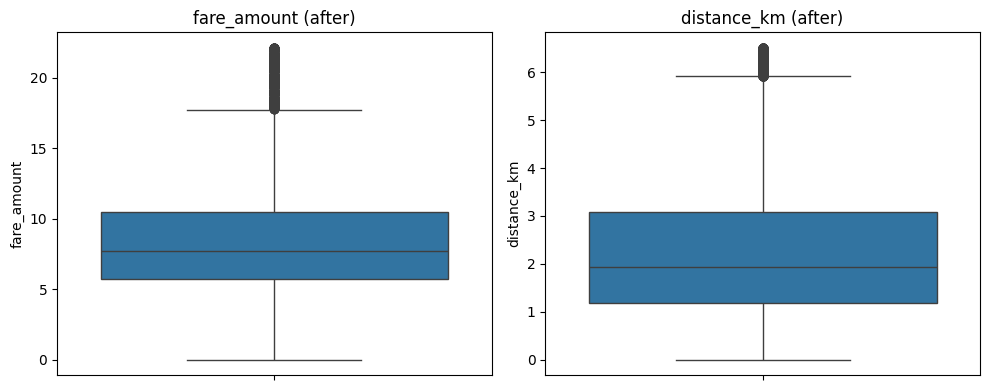

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df["fare_amount"], ax=axes[0]).set_title("fare_amount (after)")
sns.boxplot(y=df["distance_km"], ax=axes[1]).set_title("distance_km (after)")
plt.tight_layout()
plt.show()

## 3. Check the correlation

fare_amount        1.000000
distance_km        0.795563
passenger_count    0.017247
Name: fare_amount, dtype: float64


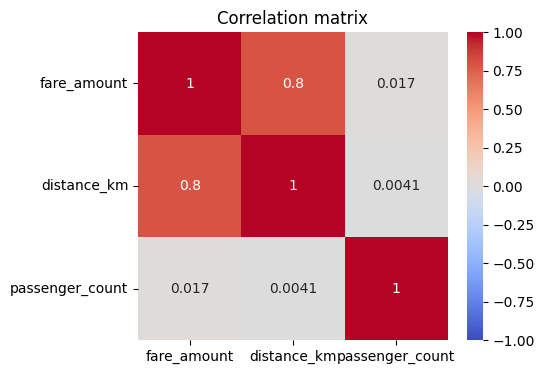

In [8]:
corr_cols = ["fare_amount", "distance_km", "passenger_count"]
corr = df[corr_cols].corr()
print(corr["fare_amount"].sort_values(ascending=False))

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

## 4. Linear regression and random forest regression

In [9]:
features = ["distance_km", "passenger_count"]
X = df[features]
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)

## Evaluate models: R2, RMSE

In [10]:
results = []
for name, model in [("Linear Regression", lr), ("Random Forest", rf)]:
    preds = model.predict(X_test)
    r2 = r2_score(y_test, preds)
    rmse = mean_squared_error(y_test, preds) ** 0.5
    results.append({"Model": name, "R2": r2, "RMSE": rmse})

pd.DataFrame(results)

,Model,R2,RMSE
0,Linear Regression,0.629833,2.276871
1,Random Forest,0.503612,2.636635
